# Features


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/books_clean.csv")
y = df["category"]

In [3]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def evaluate(model, X, y):
    scores = cross_validate(model, X, y, cv=cv, scoring=["accuracy", "f1_macro"])
    return {
        "accuracy": f"{scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}",
        "f1_macro": f"{scores['test_f1_macro'].mean():.3f} ± {scores['test_f1_macro'].std():.3f}",
    }


StratifiedKFold() splits the books into 5 parts (n_splits=5) and tests on a different part everytime. We have fewer fiction books so we use stratification so every fold contains enought books of both. F1 macro makes it so that both the classes count equally even tho they are imbalanced

In [4]:
from sklearn.dummy import DummyClassifier

evaluate(DummyClassifier(strategy="most_frequent"), df[["title"]], y)

{'accuracy': '0.629 ± 0.000', 'f1_macro': '0.386 ± 0.000'}

DummyClassifier(strategy="most_frequent") predicts the most common class for every book. This gives us the baseline that we talked about in part 2. Guessing nonfiction is right 63% of the time. Next we are going to use what we discoverd in our exploration to make the model more accurate.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

text = df["title"] + " " + df["description"]

test_1 = evaluate(make_pipeline(TfidfVectorizer(), MultinomialNB()), text, y)
test_2 = evaluate(make_pipeline(TfidfVectorizer(stop_words='english'), MultinomialNB()), text, y)
test_3 = evaluate(make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000)), text, y)
test_4 = evaluate(make_pipeline(TfidfVectorizer(stop_words='english'), LogisticRegression(max_iter=1000)), text, y)
print(f"Test 1: {test_1}")
print(f"Test 2: {test_2}")
print(f"Test 3: {test_3}")
print(f"Test 4: {test_4}")

Test 1: {'accuracy': '0.629 ± 0.000', 'f1_macro': '0.386 ± 0.000'}
Test 2: {'accuracy': '0.629 ± 0.000', 'f1_macro': '0.386 ± 0.000'}
Test 3: {'accuracy': '0.663 ± 0.042', 'f1_macro': '0.483 ± 0.089'}
Test 4: {'accuracy': '0.629 ± 0.000', 'f1_macro': '0.386 ± 0.000'}


Something is not working here since it justs give about the same accuracy

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

text = df["title"] + " " + df["description"]

text_models = {
    # fixed
    "Counts + NB": make_pipeline(CountVectorizer(), MultinomialNB()),
    "Counts (stop) + NB": make_pipeline(CountVectorizer(stop_words="english"), MultinomialNB()),
    "TF-IDF + LR balanced": make_pipeline(TfidfVectorizer(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "TF-IDF (stop) + LR balanced": make_pipeline(TfidfVectorizer(stop_words="english"), LogisticRegression(class_weight="balanced", max_iter=1000)),
}

for name, model in text_models.items():
    print(f"{name} {evaluate(model, text, y)}")


Counts + NB {'accuracy': '0.789 ± 0.046', 'f1_macro': '0.731 ± 0.077'}
Counts (stop) + NB {'accuracy': '0.840 ± 0.023', 'f1_macro': '0.822 ± 0.032'}
TF-IDF + LR balanced {'accuracy': '0.846 ± 0.043', 'f1_macro': '0.827 ± 0.049'}
TF-IDF (stop) + LR balanced {'accuracy': '0.829 ± 0.048', 'f1_macro': '0.802 ± 0.057'}


Now we got better accuracys. Used CountVectorizer instead of TfidVectorizer() and set class_weight to balanced in LogisticRegression

In [18]:
for C in [1, 10, 100, 1000]:
    model = make_pipeline(TfidfVectorizer(), LogisticRegression(C=C, class_weight="balanced", max_iter=1000))
    print(f"C={C:<4} {evaluate(model, text, y)}")


C=1    {'accuracy': '0.846 ± 0.043', 'f1_macro': '0.827 ± 0.049'}
C=10   {'accuracy': '0.857 ± 0.040', 'f1_macro': '0.838 ± 0.049'}
C=100  {'accuracy': '0.874 ± 0.039', 'f1_macro': '0.857 ± 0.048'}
C=1000 {'accuracy': '0.869 ± 0.046', 'f1_macro': '0.849 ± 0.058'}


In [19]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(
    make_pipeline(TfidfVectorizer(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    {"logisticregression__C": [1, 10, 100, 1000]},
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
    scoring="f1_macro",
)
evaluate(search, text, y)


{'accuracy': '0.869 ± 0.046', 'f1_macro': '0.849 ± 0.058'}

In [7]:
def title_features(titles):
    return pd.DataFrame({
        "has_colon": titles.str.contains(":").astype(int),
        "has_series": titles.str.contains(r"#\d").astype(int),
        "title_words": titles.str.split().str.len(),
    })

X_title = title_features(df["title"])
X_title.head()

,has_colon,has_series,title_words
0,0,0,1
1,0,1,4
2,0,0,5
3,0,0,1
4,0,1,8


astype(int) turns True/False into 1/0

In [8]:
X_title.groupby(y).mean() 

,has_colon,has_series,title_words
category,,,
Fiction,0.015385,0.261538,3.707692
Nonfiction,0.709091,0.036364,9.409091


This is to check that we have the same numbers we got in our exploration

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

title_model = make_pipeline(StandardScaler(), LogisticRegression())

print("colon only:", evaluate(title_model, X_title[["has_colon"]], y))
print("all three: ", evaluate(title_model, X_title, y))

colon only: {'accuracy': '0.811 ± 0.050', 'f1_macro': '0.810 ± 0.049'}
all three:  {'accuracy': '0.823 ± 0.058', 'f1_macro': '0.818 ± 0.059'}


Using our findings from our exploration we managed to get a 82% score which is pretty good. Most improvement comes from the colon

In [10]:
print("without colon:", evaluate(title_model, X_title[["has_series", "title_words"]], y))
print("without series:", evaluate(title_model, X_title[["has_colon", "title_words"]], y))
print("without title_words:", evaluate(title_model, X_title[["has_colon", "has_series"]], y))

without colon: {'accuracy': '0.817 ± 0.014', 'f1_macro': '0.803 ± 0.011'}
without series: {'accuracy': '0.817 ± 0.053', 'f1_macro': '0.815 ± 0.053'}
without title_words: {'accuracy': '0.811 ± 0.050', 'f1_macro': '0.810 ± 0.049'}


Just wanted to check how well they perform if we leave something out.

In [11]:
title_model.fit(X_title, y)
pd.Series(title_model[-1].coef_[0], index=X_title.columns)


has_colon      1.169454
has_series    -0.658910
title_words    1.832697
dtype: float64

This shows what the model has learnt. A positive coefficient pushes towards Nonfiction while a negative pushes towards Fiction.

Lets check how the image features would perform

In [22]:
from PIL import Image, ImageStat

def cover_stats(path):
    img = Image.open("../data/raw/" + path).convert("RGB")
    red, green, blue = ImageStat.Stat(img).mean
    return {
        "brightness": ImageStat.Stat(img.convert("L")).mean[0],
        "red": red, "green": green, "blue": blue,
        "saturation": ImageStat.Stat(img.convert("HSV")).mean[1],
    }

X_img = pd.DataFrame([cover_stats(p) for p in df["image_path"]])
image_model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
evaluate(image_model, X_img, y)


{'accuracy': '0.497 ± 0.039', 'f1_macro': '0.474 ± 0.037'}

The image model performed bad as i predicted in the exploration. I am going to scrap the idea and focus on the text model instead.

Lets combine the text model and title model

In [23]:
from sklearn.compose import ColumnTransformer

X_best = X_title.copy()
X_best["text"] = text

best_model = GridSearchCV(
    make_pipeline(
        ColumnTransformer([
            ("text", TfidfVectorizer(), "text"),
            ("title", StandardScaler(), list(X_title.columns)),
        ]),
        LogisticRegression(class_weight="balanced", max_iter=1000),
    ),
    {"logisticregression__C": [1, 10, 100, 1000]},
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
    scoring="f1_macro",
)
evaluate(best_model, X_best, y)


{'accuracy': '0.880 ± 0.038', 'f1_macro': '0.877 ± 0.038'}

This model gives us a 88% accuracy which is up from text alone

              precision    recall  f1-score   support

     Fiction      0.768     0.969     0.857        65
  Nonfiction      0.978     0.827     0.897       110

    accuracy                          0.880       175
   macro avg      0.873     0.898     0.877       175
weighted avg      0.900     0.880     0.882       175



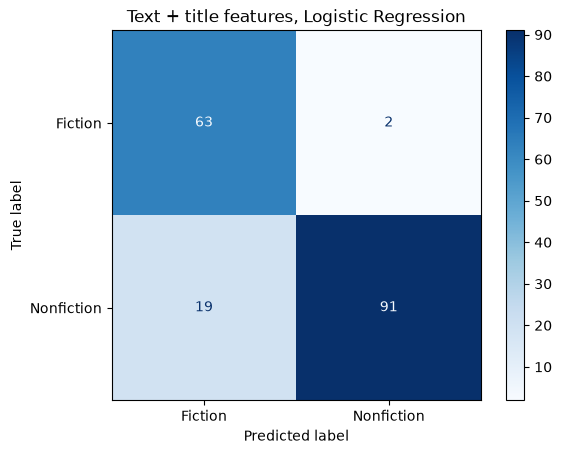

In [24]:
from pathlib import Path
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

pred = cross_val_predict(best_model, X_best, y, cv=cv)
print(classification_report(y, pred, digits=3))

ConfusionMatrixDisplay.from_predictions(y, pred, cmap="Blues")
plt.title("Text + title features, Logistic Regression")
Path("../report/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("../report/figures/confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()


In [25]:
wrong = df[pred != y].assign(predicted=pred[pred != y])
wrong[["title", "category", "predicted"]]


,title,category,predicted
7,The Regional Office Is Under Attack!,Fiction,Nonfiction
35,Hystopia: A Novel,Fiction,Nonfiction
67,Reasons to Stay Alive,Nonfiction,Fiction
82,The Genius of Birds,Nonfiction,Fiction
103,Abstract City,Nonfiction,Fiction
110,"Mother, Can You Not?",Nonfiction,Fiction
115,Why Not Me?,Nonfiction,Fiction
119,Rising Strong,Nonfiction,Fiction
123,I Will Find You,Nonfiction,Fiction
131,In Cold Blood,Nonfiction,Fiction
